<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/03_baseline_model_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Baseline Model and Experiments (U-Net on CamVid)

**What is this notebook for?**
It trains a deep learning model that looks at a street image and paints every pixel with its class (road, car, building, sky, pedestrian...). This task is called *semantic segmentation*.

**Where it fits in the project**
- Notebook 01: download CamVid and explore the data (images, masks, class distribution).
- Notebook 02: define the preprocessing and data augmentation pipelines.
- **Notebook 03 (this one): train the baseline model and compare 3 experiments.**

**Notebook map**
| Section | What happens |
|---|---|
| 1. Setup and model | Install libraries and create the U-Net with a ResNet34 encoder |
| 2. Data | Download CamVid, build train / val / test sets and DataLoaders |
| 3. Loss, optimizer and metric | How the model is told how wrong it is, and how we score it (mIoU) |
| 4. Training functions | The code that teaches (train) and checks (validate) the model |
| 5. Training | Train the main model for 10 epochs (this is Experiment 3) |
| 6. Test evaluation | Score the model on unseen test images and look at predictions |
| 7. Experiments | Train 2 extra models to measure what pretraining and augmentation add |
| 7.3 Comparison | Table and images comparing the 3 experiments |

**Quick glossary**
- **Epoch:** one full pass of the model over all the training images.
- **Pretrained (ImageNet):** the model starts with knowledge learned from millions of general photos instead of starting from zero.
- **Data augmentation:** random changes (flip, brightness, blur) applied to training images so the model sees more variety.
- **Train / Val / Test:** train = the model learns from it, val = checked during training to pick the best version, test = final exam on images never used before.
- **mIoU:** how much the predicted mask overlaps the real mask, averaged over classes. 0 = nothing right, 1 = perfect.

---
## 1. Setup and model
The next cell installs the libraries and creates a **U-Net** (an encoder-decoder network designed for segmentation) whose encoder is a **ResNet34** pretrained on ImageNet. It also defines the basic settings: 12 classes (11 real classes plus class 11 = "void/unlabelled", which is ignored when training and scoring).

In [ ]:
!pip install -q -U segmentation-models-pytorch albumentations opencv-python-headless

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# Define hyperparameters and model specs
ENCODER = 'resnet34'       # Pretrained backbone
ENCODER_WEIGHTS = 'imagenet'
NUM_CLASSES = 12           # CamVid (SegNet version): classes 0-10 + class 11 = unlabelled/void
VOID_CLASS = 11            # Ignored in the loss and in the metrics
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Instantiate the U-Net architecture with the selected backbone
model = smp.Unet(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=3,
    classes=NUM_CLASSES
)

model = model.to(DEVICE)
print(f"Model successfully loaded on device: {DEVICE}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model successfully loaded on device: cuda


## 2. Data: CamVid and DataLoaders
The next cell prepares everything the model will be fed with:
- **Dataset:** CamVid, photos taken from a car driving through a city. Each photo comes with a *mask*: an image where every pixel stores the class of what is there (road, car, sky...). The masks are the "correct answers" used to teach and to score the model.
- **Splits:** the images are divided into train, validation and test sets (the numbers are printed when the cell runs).
- **Preprocessing:** every image is resized to 256x256 and normalized with the ImageNet mean and std (same pipelines as notebook 02). Only the **train** set also gets random augmentation (flip, mild brightness/contrast, blur). Val and test are never augmented, so scores are always measured on the same untouched images.
- **Masks:** converted to integer class indices (0-11), the format the loss function needs.
- **DataLoaders:** they hand the images to the model in small batches of 8. The last lines print the shapes and class values of one batch as a sanity check.

In [ ]:
import zipfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

# 1. Download and extract CamVid (each Colab runtime starts empty)
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
if not EXTRACTED_DIR.exists():
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()

def load_camvid_split(txt_filename: str, base_dir: Path) -> pd.DataFrame:
    """Parses a CamVid split file keeping only the parent folder and file name."""
    image_paths, mask_paths = [], []
    with open(base_dir / "CamVid" / txt_filename, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)
assert len(df_train) > 0, "df_train is empty: check the extracted folder structure"
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# 2. Preprocessing pipelines (same as notebook 02)
IMAGE_HEIGHT, IMAGE_WIDTH = 256, 256
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

train_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.Normalize(mean=tuple(MEAN), std=tuple(STD)),
    ToTensorV2()
], is_check_shapes=False)

valid_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=tuple(MEAN), std=tuple(STD)),
    ToTensorV2()
], is_check_shapes=False)

# 3. Dataset: returns a normalized image tensor and a LONG mask tensor
class CamVidDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image = cv2.cvtColor(cv2.imread(self.df.loc[idx, "image_path"]), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.df.loc[idx, "mask_path"], cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=image, mask=mask)
        # CrossEntropy / Dice losses require class indices as int64
        return out["image"], out["mask"].long()

# 4. DataLoaders
BATCH_SIZE = 8
train_loader = DataLoader(CamVidDataset(df_train, train_transforms), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(CamVidDataset(df_val, valid_transforms), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2)
test_loader = DataLoader(CamVidDataset(df_test, valid_transforms), batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2)

# 5. Sanity check: shapes, dtypes and class index range
images, masks = next(iter(train_loader))
print(f"Images: {tuple(images.shape)} {images.dtype} | Masks: {tuple(masks.shape)} {masks.dtype}")
print(f"Unique mask values in batch: {masks.unique().tolist()}")
assert masks.max() < NUM_CLASSES, "Mask contains class indices >= NUM_CLASSES"

Train: 367 | Val: 101 | Test: 233
Images: (8, 3, 256, 256) torch.float32 | Masks: (8, 256, 256) torch.int64
Unique mask values in batch: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


## 3. Loss, optimizer and metric
The next cell defines how the model learns and how we score it:
- **Loss function = CrossEntropy + Dice.** It measures how wrong the predicted mask is. CrossEntropy checks pixel by pixel, Dice checks how well whole regions overlap (useful for small classes). The void class (11) is ignored.
- **Optimizer (Adam):** the algorithm that adjusts the model's weights after each batch to make the loss smaller.
- **Scheduler:** automatically halves the learning rate if the validation loss does not improve for 3 epochs.
- **Metric = mIoU (mean Intersection over Union):** for each class, overlap between prediction and real mask divided by their total combined area, averaged over classes. It is the main score we report.

In [ ]:
# 1. Loss function: CrossEntropy + Dice Loss, ignoring the void class
ce_loss = nn.CrossEntropyLoss(ignore_index=VOID_CLASS)
dice_loss = smp.losses.DiceLoss(mode='multiclass', from_logits=True, ignore_index=VOID_CLASS)

def criterion(outputs, masks):
    return ce_loss(outputs, masks) + dice_loss(outputs, masks)

# 2. Optimizer: Adam with adaptive learning rate
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# 3. Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# 4. Metric: mean Intersection over Union computed from a confusion matrix
def update_confusion(confusion, preds, masks):
    valid = masks != VOID_CLASS
    idx = masks[valid] * NUM_CLASSES + preds[valid]
    confusion += torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    return confusion

def miou_from_confusion(confusion):
    confusion = confusion.float()
    intersection = torch.diag(confusion)
    union = confusion.sum(0) + confusion.sum(1) - intersection
    iou = intersection / union.clamp(min=1)
    present = union[:VOID_CLASS] > 0   # only classes that appear (void excluded)
    return iou[:VOID_CLASS][present].mean().item(), iou

print("Loss function, optimizer, scheduler and metrics initialized.")

Loss function, optimizer, scheduler and metrics initialized.


## 4. Training and validation functions
The next cell only *defines* two functions (nothing is trained yet):
- **train_one_epoch:** the model looks at all training batches, measures its error and updates its weights. This is where it learns.
- **validate_one_epoch:** the model is evaluated on the validation set **without learning**. It returns the validation loss and the mIoU, which tell us how well it handles images it has not trained on.

In [ ]:
from tqdm import tqdm

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, masks in tqdm(dataloader, leave=False):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(dataloader)


def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)
            running_loss += loss.item()

            confusion = update_confusion(confusion, outputs.argmax(dim=1), masks)

    miou, _ = miou_from_confusion(confusion)
    return running_loss / len(dataloader), miou

## 5. Training the main model (this is Experiment 3)
The next cell runs the training for 10 epochs: ImageNet-pretrained ResNet34 + data augmentation. After each epoch it prints the train loss, validation loss and validation mIoU, and it saves the best version (lowest validation loss) to `best_segmentation_model.pth`.
This is the slowest step of the notebook, so use a GPU runtime.

In [ ]:
EPOCHS = 10
best_val_loss = float('inf')
history = {'train_loss': [], 'val_loss': [], 'val_miou': []}

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_miou = validate_one_epoch(model, val_loader, criterion, DEVICE)

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_miou'].append(val_miou)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val mIoU: {val_miou:.4f}")

    # Save best model parameters
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best_segmentation_model.pth')
        print(" -> Model saved (best validation loss).")

Epoch [1/10] | Train Loss: 1.7196 | Val Loss: 1.3066 | Val mIoU: 0.3819
 -> Model saved (best validation loss).


Epoch [2/10] | Train Loss: 1.0901 | Val Loss: 1.1625 | Val mIoU: 0.3965
 -> Model saved (best validation loss).


Epoch [3/10] | Train Loss: 0.9723 | Val Loss: 1.0190 | Val mIoU: 0.4063
 -> Model saved (best validation loss).


Epoch [4/10] | Train Loss: 0.9416 | Val Loss: 0.9965 | Val mIoU: 0.4126
 -> Model saved (best validation loss).


Epoch [5/10] | Train Loss: 0.8765 | Val Loss: 1.0340 | Val mIoU: 0.4033


Epoch [6/10] | Train Loss: 0.8421 | Val Loss: 0.8091 | Val mIoU: 0.4914
 -> Model saved (best validation loss).


Epoch [7/10] | Train Loss: 0.8193 | Val Loss: 0.8088 | Val mIoU: 0.4955
 -> Model saved (best validation loss).


Epoch [8/10] | Train Loss: 0.8065 | Val Loss: 0.8901 | Val mIoU: 0.4781


Epoch [9/10] | Train Loss: 0.7785 | Val Loss: 1.3747 | Val mIoU: 0.4332


Epoch [10/10] | Train Loss: 0.7583 | Val Loss: 0.7338 | Val mIoU: 0.5533
 -> Model saved (best validation loss).


## 6. Test evaluation and prediction visualization
The next cell loads the best saved model and:
1. Computes the **test mIoU** on all the test images (the final score of this model).
2. Shows 3 test examples side by side: the input image, the real mask (ground truth) and the mask predicted by the model. The same color scale is used in both masks so colors can be compared directly.

Test mIoU (void class excluded): 0.4421


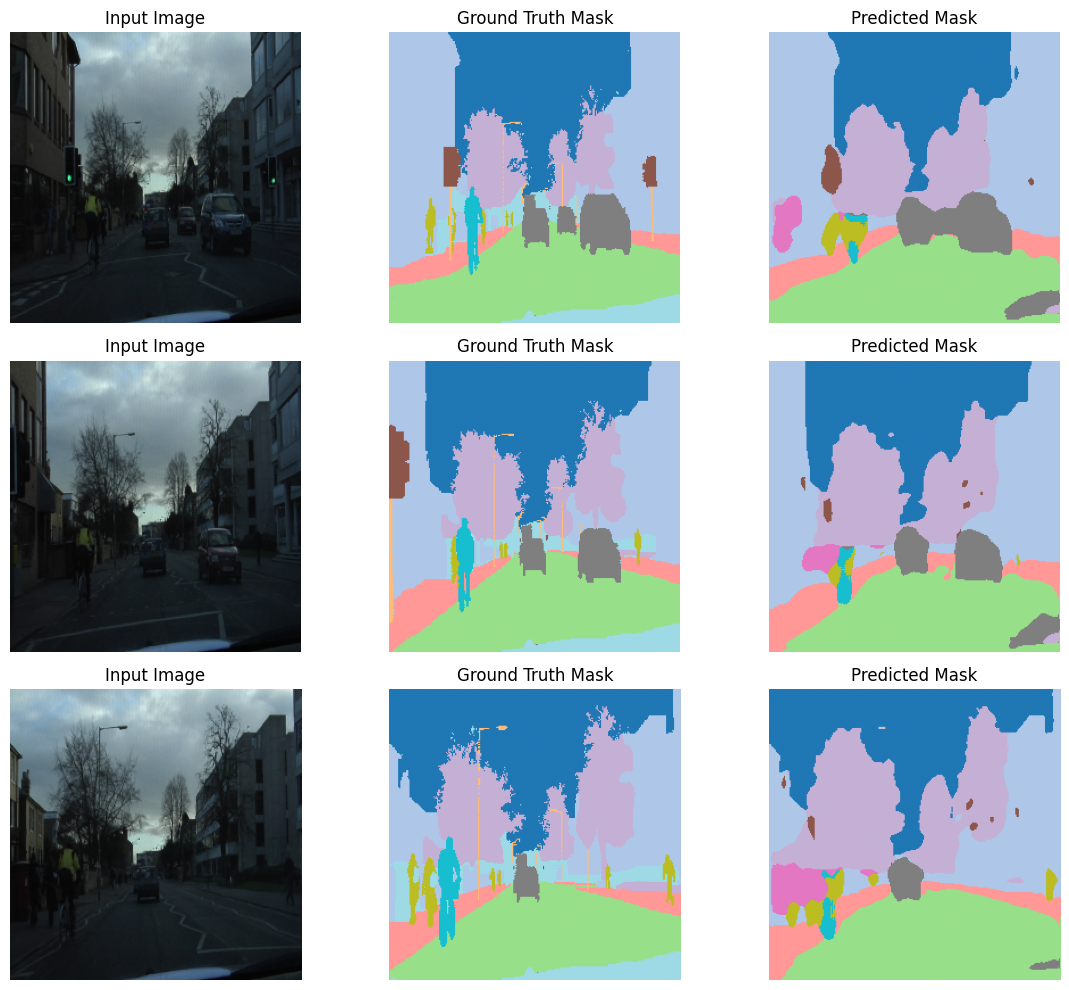

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model.load_state_dict(torch.load('best_segmentation_model.pth', map_location=DEVICE))
model.eval()

# Quantitative evaluation on the full test set
confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        confusion = update_confusion(confusion, model(images).argmax(dim=1), masks)
test_miou, per_class_iou = miou_from_confusion(confusion)
print(f"Test mIoU (void class excluded): {test_miou:.4f}")

# Qualitative evaluation: one batch from the test loader
images, masks = next(iter(test_loader))
images, masks = images.to(DEVICE), masks.to(DEVICE)

with torch.no_grad():
    preds = torch.argmax(model(images), dim=1)

# Plot comparison: Original Image vs Ground Truth vs Predicted Mask
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for i in range(3):
    # Undo the ImageNet normalization (same mean/std as the data pipeline)
    img = (images[i].cpu().permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")

    # Same color scale for ground truth and prediction so colors are comparable
    axes[i, 1].imshow(masks[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(preds[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)
    axes[i, 2].set_title("Predicted Mask")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## 7. Experiments: what do pretraining and augmentation add?
Instead of only training one model, we train **three versions** of the same U-Net (ResNet34 encoder) changing one thing at a time. This kind of comparison is called an *ablation study*, and it lets us say *why* the final model works better, not only *that* it works.

| Experiment | Encoder starts from | Data augmentation | Where it is trained |
|---|---|---|---|
| **Exp 1** - Baseline (from scratch) | Random weights | No | Section 7.2 |
| **Exp 2** - Transfer learning | ImageNet weights | No | Section 7.2 |
| **Exp 3** - Transfer learning + augmentation | ImageNet weights | Yes | Already trained in section 5 |

**Everything else is identical in the three experiments:** same architecture, same loss, same optimizer and learning rate, same 10 epochs, same validation set and same test set. Because of that, the difference in test mIoU can be attributed to the one thing that changed.
- Exp 1 vs Exp 2: effect of **pretraining on ImageNet**.
- Exp 2 vs Exp 3: effect of **data augmentation**.

### 7.1 Preparation
The next cell does two small things before running the experiments:
1. Creates a training DataLoader **without augmentation** (it reuses the validation pipeline: only resize and normalize). It is used by Exp 1 and Exp 2.
2. Defines `evaluate_test_miou`, a helper that scores any model on the test set, and stores the test mIoU of the main model from section 6 as the result of Exp 3 (it is not retrained).

In [ ]:
# ==========================================
# EXPERIMENTS 1 & 2: DATALOADER WITHOUT AUGMENTATION
# ==========================================
# Reuse valid_transforms (only Resize + Normalize, no random flips/brightness/blur)
train_loader_no_aug = DataLoader(
    CamVidDataset(df_train, valid_transforms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

def evaluate_test_miou(model_to_eval, loader):
    """Helper function to compute Test mIoU using your exact confusion matrix logic."""
    model_to_eval.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        for imgs, msks in loader:
            imgs, msks = imgs.to(DEVICE), msks.to(DEVICE)
            conf = update_confusion(conf, model_to_eval(imgs).argmax(dim=1), msks)
    miou, _ = miou_from_confusion(conf)
    return miou

# Save Experiment 3 results (the model you already trained above)
exp3_test_miou = test_miou
print(f"Loaded Exp 3 (Pretrained + Augmentation) Test mIoU: {exp3_test_miou:.4f}")

Loaded Exp 3 (Pretrained + Augmentation) Test mIoU: 0.4421


## 7.2 Running Experiments 1 and 2
The next cell defines `run_ablation_experiment`, a function that trains one complete model from zero and returns it with its test score. For each experiment it:
1. Builds a **fresh** U-Net (so nothing is carried over from the other experiments).
2. Trains it for 10 epochs with the same loss, optimizer and learning rate scheduler as the main model, printing train loss, validation loss and validation mIoU.
3. Keeps the best version (lowest validation loss) in its own file.
4. Reloads that best version and computes its **test mIoU**.

It then runs the two experiments:
- **Experiment 1:** encoder starts from random weights (`encoder_weights=None`), no augmentation.
- **Experiment 2:** encoder starts from ImageNet weights, no augmentation.

Each experiment trains a full model, so this cell takes about twice as long as the main training.

In [ ]:
# ==========================================
# RUN EXPERIMENT 1 (SCRATCH) & EXPERIMENT 2 (PRETRAINED ONLY)
# ==========================================
def run_ablation_experiment(exp_title, encoder_weights, loader, save_filename):
    print(f"\n--- Running {exp_title} ---")
    exp_model = smp.Unet(
        encoder_name=ENCODER,
        encoder_weights=encoder_weights,
        in_channels=3,
        classes=NUM_CLASSES
    ).to(DEVICE)

    exp_optimizer = torch.optim.Adam(exp_model.parameters(), lr=1e-3, weight_decay=1e-4)
    exp_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(exp_optimizer, mode='min', patience=3, factor=0.5)

    best_loss = float('inf')
    for epoch in range(EPOCHS):
        t_loss = train_one_epoch(exp_model, loader, criterion, exp_optimizer, DEVICE)
        v_loss, v_miou = validate_one_epoch(exp_model, val_loader, criterion, DEVICE)
        exp_scheduler.step(v_loss)

        print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val mIoU: {v_miou:.4f}")
        if v_loss < best_loss:
            best_loss = v_loss
            torch.save(exp_model.state_dict(), save_filename)

    # Load best weights for test evaluation
    exp_model.load_state_dict(torch.load(save_filename, map_location=DEVICE))
    final_test_miou = evaluate_test_miou(exp_model, test_loader)
    print(f"--> {exp_title} Final Test mIoU: {final_test_miou:.4f}")
    return exp_model, final_test_miou

# Run Exp 1: From Scratch (encoder_weights=None) + No Augmentation
model_exp1, exp1_test_miou = run_ablation_experiment(
    exp_title="Exp 1: Baseline (Scratch, No Aug)",
    encoder_weights=None,
    loader=train_loader_no_aug,
    save_filename="best_model_exp1.pth"
)

# Run Exp 2: Transfer Learning (ImageNet) + No Augmentation
model_exp2, exp2_test_miou = run_ablation_experiment(
    exp_title="Exp 2: Transfer Learning (ImageNet, No Aug)",
    encoder_weights="imagenet",
    loader=train_loader_no_aug,
    save_filename="best_model_exp2.pth"
)


--- Running Exp 1: Baseline (Scratch, No Aug) ---


Epoch [1/10] | Train Loss: 1.8711 | Val Loss: 1.6380 | Val mIoU: 0.2578


Epoch [2/10] | Train Loss: 1.2598 | Val Loss: 1.4618 | Val mIoU: 0.3167


Epoch [3/10] | Train Loss: 1.1242 | Val Loss: 1.2393 | Val mIoU: 0.3515


Epoch [4/10] | Train Loss: 1.0474 | Val Loss: 1.2154 | Val mIoU: 0.3478


Epoch [5/10] | Train Loss: 1.0219 | Val Loss: 1.0689 | Val mIoU: 0.4005


... (11 outputs left out)

Epoch [7/10] | Train Loss: 0.7348 | Val Loss: 0.7348 | Val mIoU: 0.5767


Epoch [8/10] | Train Loss: 0.7053 | Val Loss: 0.8165 | Val mIoU: 0.5407


Epoch [9/10] | Train Loss: 0.6217 | Val Loss: 0.7276 | Val mIoU: 0.5535


Epoch [10/10] | Train Loss: 0.6045 | Val Loss: 1.1125 | Val mIoU: 0.4422
--> Exp 2: Transfer Learning (ImageNet, No Aug) Final Test mIoU: 0.4383


**How to read the output above:** for each experiment it prints one line per epoch (train loss, validation loss, validation mIoU) and, at the end, a line with its **Final Test mIoU**. The final test mIoU is the number used to compare the experiments in the next section.

## 7.3 Comparison of the 3 experiments
The next cell puts the three models side by side:
1. **Summary table:** one row per experiment with whether it used pretraining, whether it used augmentation, and its **test mIoU**.
2. **Visual comparison:** the same 3 test images with the real mask and the mask predicted by each of the 3 models, so differences can be seen directly. The figure is also saved as `comparison_3_experiments.png`.

How to read it: Exp 1 to Exp 2 isolates the effect of **pretraining** (only that changes). Exp 2 to Exp 3 isolates the effect of **data augmentation** (only that changes).

,Experiment,Pretrained,Data Augmentation,Test mIoU
0,Exp 1: Baseline (From Scratch),No (None),No,0.3592
1,Exp 2: Transfer Learning,Yes (ImageNet),No,0.4383
2,Exp 3: Transfer Learning + Aug,Yes (ImageNet),Yes,0.4421


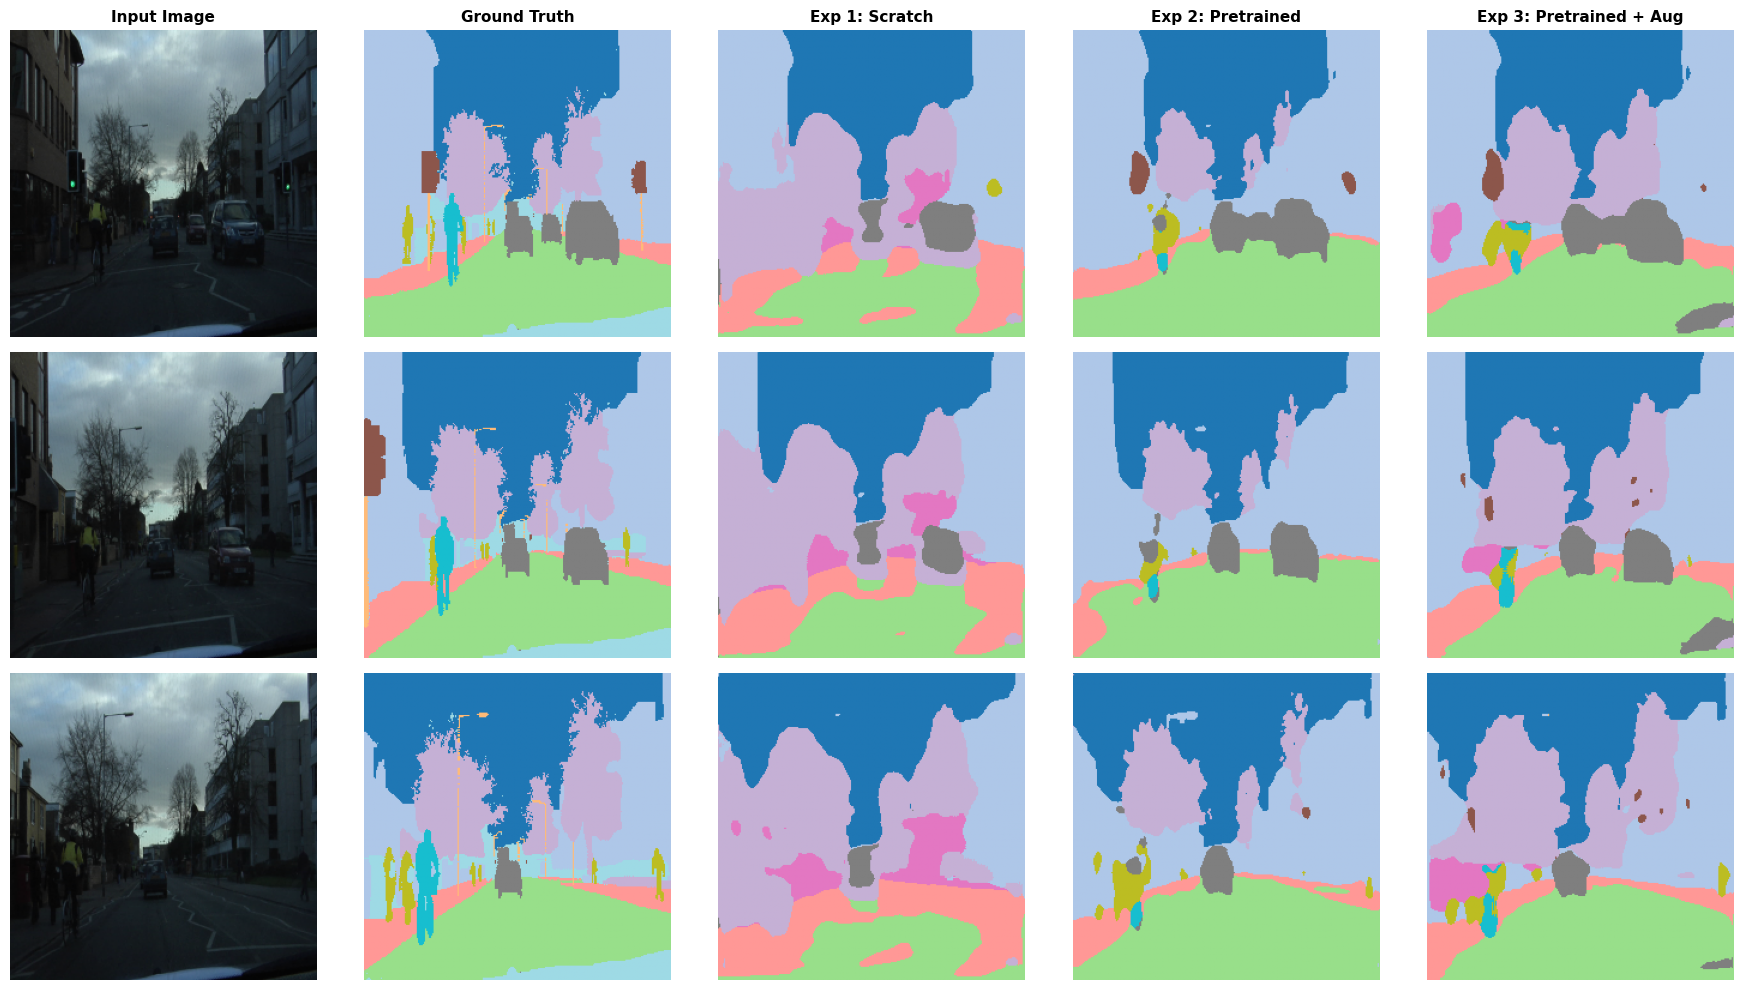

In [ ]:
# ==========================================
# QUANTITATIVE & QUALITATIVE COMPARISON (ALL 3 EXPERIMENTS)
# ==========================================
# 1. Summary Table
summary_df = pd.DataFrame([
    {"Experiment": "Exp 1: Baseline (From Scratch)", "Pretrained": "No (None)", "Data Augmentation": "No", "Test mIoU": round(exp1_test_miou, 4)},
    {"Experiment": "Exp 2: Transfer Learning", "Pretrained": "Yes (ImageNet)", "Data Augmentation": "No", "Test mIoU": round(exp2_test_miou, 4)},
    {"Experiment": "Exp 3: Transfer Learning + Aug", "Pretrained": "Yes (ImageNet)", "Data Augmentation": "Yes", "Test mIoU": round(exp3_test_miou, 4)},
])
display(summary_df)

# 2. Side-by-Side Visual Comparison (3 Test Samples)
model_exp1.eval()
model_exp2.eval()
model.eval()  # Your Exp 3 model already loaded with 'best_segmentation_model.pth'

images, masks = next(iter(test_loader))
images, masks = images.to(DEVICE), masks.to(DEVICE)

with torch.no_grad():
    preds_exp1 = torch.argmax(model_exp1(images), dim=1)
    preds_exp2 = torch.argmax(model_exp2(images), dim=1)
    preds_exp3 = torch.argmax(model(images), dim=1)

fig, axes = plt.subplots(3, 5, figsize=(18, 10))
col_titles = ["Input Image", "Ground Truth", "Exp 1: Scratch", "Exp 2: Pretrained", "Exp 3: Pretrained + Aug"]

for i in range(3):
    img = (images[i].cpu().permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

    axes[i, 0].imshow(img)
    axes[i, 1].imshow(masks[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)
    axes[i, 2].imshow(preds_exp1[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)
    axes[i, 3].imshow(preds_exp2[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)
    axes[i, 4].imshow(preds_exp3[i].cpu().numpy(), cmap='tab20', vmin=0, vmax=NUM_CLASSES - 1)

    for col in range(5):
        if i == 0:
            axes[i, col].set_title(col_titles[col], fontsize=11, fontweight='bold')
        axes[i, col].axis("off")

plt.tight_layout()
plt.savefig("comparison_3_experiments.png", dpi=150, bbox_inches="tight")
plt.show()